# Evaluación de preprocesamiento OCR

Copia experimental del flujo original. Las imágenes fuente no se modifican. El informe completo está en [`OCR_EVALUATION.md`](OCR_EVALUATION.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'results' / 'ocr_evaluation.json').exists():
    ROOT = ROOT / 'ocr-phishing'
payload = json.loads((ROOT / 'results' / 'ocr_evaluation.json').read_text(encoding='utf-8'))

## Métricas ejecutadas

In [2]:
metrics = [{'imagen': 'ejcorreo', 'variante': 'original', 'CER': 0.031, 'WER': 0.1026, 'confianza_media': 0.8768, 'regiones': 18, 'segundos': 4.267}, {'imagen': 'ejcorreo', 'variante': 'grayscale', 'CER': 0.0332, 'WER': 0.1154, 'confianza_media': 0.8408, 'regiones': 18, 'segundos': 3.996}, {'imagen': 'ejcorreo', 'variante': 'upscale_2x', 'CER': 0.0111, 'WER': 0.0385, 'confianza_media': 0.8903, 'regiones': 17, 'segundos': 9.834}, {'imagen': 'ejcorreo', 'variante': 'upscale_clahe', 'CER': 0.031, 'WER': 0.0769, 'confianza_media': 0.8825, 'regiones': 17, 'segundos': 9.587}, {'imagen': 'ejcorreo', 'variante': 'upscale_otsu', 'CER': 0.0199, 'WER': 0.0897, 'confianza_media': 0.8264, 'regiones': 17, 'segundos': 9.436}, {'imagen': 'ejcorreo', 'variante': 'upscale_denoise_otsu', 'CER': 0.0177, 'WER': 0.0641, 'confianza_media': 0.8346, 'regiones': 17, 'segundos': 9.422}, {'imagen': 'ejwpp', 'variante': 'original', 'CER': 0.0081, 'WER': 0.0435, 'confianza_media': 0.7591, 'regiones': 7, 'segundos': 2.673}, {'imagen': 'ejwpp', 'variante': 'grayscale', 'CER': 0.0081, 'WER': 0.0435, 'confianza_media': 0.7889, 'regiones': 7, 'segundos': 2.708}, {'imagen': 'ejwpp', 'variante': 'upscale_2x', 'CER': 0.0407, 'WER': 0.1739, 'confianza_media': 0.7733, 'regiones': 9, 'segundos': 8.77}, {'imagen': 'ejwpp', 'variante': 'upscale_clahe', 'CER': 0.0325, 'WER': 0.1304, 'confianza_media': 0.8434, 'regiones': 10, 'segundos': 10.791}, {'imagen': 'ejwpp', 'variante': 'upscale_otsu', 'CER': 0.1626, 'WER': 0.1739, 'confianza_media': 0.8351, 'regiones': 8, 'segundos': 11.792}, {'imagen': 'ejwpp', 'variante': 'upscale_denoise_otsu', 'CER': 0.1626, 'WER': 0.1739, 'confianza_media': 0.8123, 'regiones': 8, 'segundos': 10.796}]
metrics_df = pd.DataFrame(metrics)
display(metrics_df.sort_values(['imagen', 'WER']))

,imagen,variante,CER,WER,confianza_media,regiones,segundos
2,ejcorreo,upscale_2x,0.0111,0.0385,0.8903,17,9.834
5,ejcorreo,upscale_denoise_otsu,0.0177,0.0641,0.8346,17,9.422
3,ejcorreo,upscale_clahe,0.0310,0.0769,0.8825,17,9.587
4,ejcorreo,upscale_otsu,0.0199,0.0897,0.8264,17,9.436
0,ejcorreo,original,0.0310,0.1026,0.8768,18,4.267
1,ejcorreo,grayscale,0.0332,0.1154,0.8408,18,3.996
6,ejwpp,original,0.0081,0.0435,0.7591,7,2.673
7,ejwpp,grayscale,0.0081,0.0435,0.7889,7,2.708
9,ejwpp,upscale_clahe,0.0325,0.1304,0.8434,10,10.791
8,ejwpp,upscale_2x,0.0407,0.1739,0.7733,9,8.770


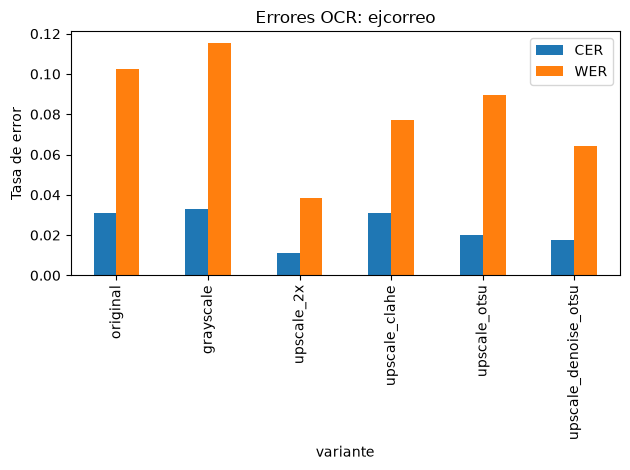

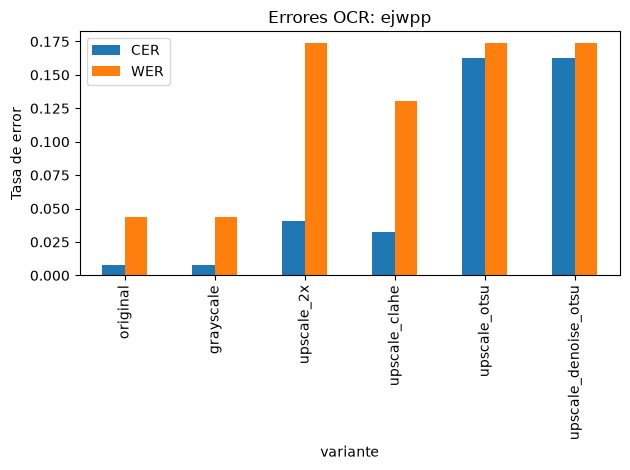

In [3]:
for image, group in metrics_df.groupby('imagen'):
    group.set_index('variante')[['CER', 'WER']].plot(kind='bar', title=f'Errores OCR: {image}')
    plt.ylabel('Tasa de error'); plt.tight_layout(); plt.show()

## Textos y conservación de entidades

In [4]:
for image_name, image in payload['images'].items():
    print(f'\n### {image_name}')
    for variant, result in image['variants'].items():
        print(f'\n[{variant}] entidades={result["important_terms"]}')
        print(result['text'])


### ejcorreo

[original] entidades={'contact@growthdot.com': True, 'Email Tracking': True, 'Europe/Kyiv': True}
Welcome to Email Tracking
7
9
Via web form
Agent
Internal
minute ago
Assign
Email reading has been tracked by Email Tracking app
Email was read
seconds after it was sent
Sent on 13.05.49 9 January 2024 Europe/Kyiv
Read on 13.05.56 9 January 2024 Europe/Kyiv
Email body:
Welcome to Email Tracking!
If you have any questions or need any assistance; please do not hesitate to contact
our customer
support team at contact@growthdot.com. We are here to help you

[grayscale] entidades={'contact@growthdot.com': False, 'Email Tracking': True, 'Europe/Kyiv': True}
Welcome to Email Tracking
7
9
Via web form
Agent
Internal
minute ago
Assign
Email reading has been tracked by Email Tracking app
Email was read
seconds after it was sent
Sent on 13.05.49 9 January 2024 Europe/Kyiv
Read on 13.05.56 9 January 2024 Europe/Kyiv
Email body:
Welcome to Email Tracking!
If you have any questions or nee

## Repetición del experimento

Ejecutar `evaluate_ocr.py` desde `ocr-phishing/`. Para equipos con memoria limitada, usar `--images` y `--variants` para procesar una variante por ejecución. No enviar imágenes ni texto a servicios externos.